# Damage in Dollars: Cost, Recovery and the Predicted Map

Notebook 1 looks at whether some communities are affected more heavily than others and finds no clear income gradient once the disaster itself is taken into account. This notebook builds on that result. It puts a dollar value on the same damage map, compares those estimates with real inspection records, looks at who can actually afford to rebuild, and then repeats the analysis using the CNN’s predicted damage map instead of the original labels.

Everything runs in a few seconds using the CSV files in `data/`. No model training or image processing is involved here.



## 1. Analysis Plan

1. Convert each damage class into an estimated dollar loss across all four disaster types.

2. Validate these estimates against three independent sources: flood insurance settlements, CAL FIRE post-fire inspections, and FEMA loss verifications.

3. Compare physical damage and estimated dollar losses across different income groups.

4. Measure recovery capacity by looking at insurance take-up and federal grants across all disaster types.

5. Apply the same relief rules to the predicted damage map and compare the results with the original labels.


## 2. Real Inputs

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display


#Works whether the notebook is opened from this folder or from the repository root
REPO_ROOT = Path.cwd()

if not (REPO_ROOT / 'data').exists():
    REPO_ROOT = Path('..').resolve()

DATA = REPO_ROOT / 'data'
OUTPUT_DIR = REPO_ROOT / 'outputs' / 'damage_cost'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Reading from: {DATA}')
print(f'Writing to:   {OUTPUT_DIR}')

Reading from: D:\UNI\DLSS\satellite-disaster-damage-mapping\socio_analysis_final\data
Writing to:   D:\UNI\DLSS\satellite-disaster-damage-mapping\socio_analysis_final\outputs\damage_cost


In [ ]:
# Block groups smaller than this are too noisy to average over
MIN_BUILDINGS = 20

#The census writes a missing value as this number instead of leaving it empty
ACS_MISSING = -666666666



DISASTER_TYPE = {'hurricane-harvey': 'hurricane',
                 'hurricane-florence': 'hurricane',
                 'hurricane-michael': 'hurricane',
                 'midwest-flooding': 'flood',
                 'santa-rosa-wildfire': 'wildfire',
                 'socal-fire': 'wildfire',
                 'woolsey-fire': 'wildfire',
                 'joplin-tornado': 'tornado',
                 'tuscaloosa-tornado': 'tornado',
                 'moore-tornado': 'tornado'}

#The events with flood insurance behind them, used in sections 4 and 7
WATER_EVENTS = ['hurricane-harvey',
                'hurricane-florence',
                'hurricane-michael',
                'midwest-flooding']

#Share of a building's value lost at each damage class
LOSS_RATIO = {'no-damage': 0.00,
              'minor-damage': 0.05,
              'major-damage': 0.30,
              'destroyed': 1.00}

#The same classes read cautiously and generously, carried through as a band
LOSS_LOW = {'no-damage': 0.00,
            'minor-damage': 0.02,
            'major-damage': 0.20,
            'destroyed': 0.90}

LOSS_HIGH = {'no-damage': 0.00,
             'minor-damage': 0.10,
             'major-damage': 0.45,
             'destroyed': 1.00}

In [ ]:
#Our own damage map, the census, and five federal records
buildings = pd.read_csv(DATA / 'buildings.csv', dtype={'GEOID': str})
tracts = pd.read_csv(DATA / 'tracts.csv', dtype={'GEOID': str})
claims = pd.read_csv(DATA / 'nfip_claims.csv', dtype={'censusGeoid': str})
fema = pd.read_csv(DATA / 'fema_disaster_totals.csv')
registrations = pd.read_csv(DATA / 'fema_registrations.csv')
dins = pd.read_csv(DATA / 'calfire_dins.csv')
predictions = pd.read_csv(DATA / 'predictions.csv', dtype={'GEOID': str})


#A block-group id is always 12 digits, and a leading zero is easy to lose
buildings['GEOID'] = buildings['GEOID'].str.zfill(12)
tracts['GEOID'] = tracts['GEOID'].str.zfill(12)
predictions['GEOID'] = predictions['GEOID'].str.zfill(12)
claims['censusGeoid'] = claims['censusGeoid'].astype(str).str.zfill(12)

print(f'Loaded {len(buildings):,} buildings and {len(tracts):,} block groups')

Loaded 185,045 buildings and 308 block groups


In [4]:
for column in ['income_2017', 'median_home_value_2017']:
    tracts[column] = tracts[column].replace(ACS_MISSING, np.nan)

# Keep block groups with enough buildings and with both census variables present.
big_enough = tracts['building_count'] >= MIN_BUILDINGS
has_census = tracts['income_2017'].notna() & tracts['median_home_value_2017'].notna()

tracts = tracts[big_enough & has_census].copy()

# Give every building the income and home value of the block group it sits in.
CENSUS_COLUMNS = ['GEOID',
                  'income_2017',
                  'median_home_value_2017',
                  'renter_pct_2017']

buildings = buildings[buildings['GEOID'].isin(set(tracts['GEOID']))]
buildings = buildings.merge(tracts[CENSUS_COLUMNS], on='GEOID')
buildings['disaster_type'] = buildings['event_name'].map(DISASTER_TYPE)

print(f'Buildings: {len(buildings):,}')
print(f'Census units: {tracts["GEOID"].nunique():,}')
print(f'NFIP flood claims: {len(claims):,}')
print(f'CAL FIRE inspected structures: {len(dins):,}')
print(f'FEMA inspected households: {len(registrations):,}')

Buildings: 110,147
Census units: 295
NFIP flood claims: 8,817
CAL FIRE inspected structures: 9,395
FEMA inspected households: 133,240


## 3. Damage to Dollars

We use the same rule for every building, regardless of the disaster type:

**loss = median home value of the block group × loss ratio for its damage class**

The loss ratios are based on the HAZUS-MH building damage states. `LOSS_LOW` and `LOSS_HIGH` are used to capture the uncertainty around these estimates and provide a sensitivity range.

The approach is not hazard-specific. In other words, a destroyed house is valued in the same way whether the damage was caused by a fire, tornado, or hurricane.


In [5]:
home_value = buildings['median_home_value_2017']

# Price every building three times: the central estimate and the two brackets.
buildings['ratio'] = buildings['damage_class'].map(LOSS_RATIO)
buildings['loss'] = home_value * buildings['ratio']
buildings['loss_low'] = home_value * buildings['damage_class'].map(LOSS_LOW)
buildings['loss_high'] = home_value * buildings['damage_class'].map(LOSS_HIGH)

# Two flags that the rest of the notebook keeps asking for.
buildings['damaged'] = buildings['loss'] > 0
buildings['destroyed'] = buildings['damage_class'] == 'destroyed'

print(f'Central estimate: ${buildings["loss"].sum() / 1e9:.2f}B')
print(f'Low bracket:      ${buildings["loss_low"].sum() / 1e9:.2f}B')
print(f'High bracket:     ${buildings["loss_high"].sum() / 1e9:.2f}B')

Central estimate: $7.01B
Low bracket:      $5.95B
High bracket:     $7.76B


In [6]:
by_event = buildings.groupby(['disaster_type', 'event_name']).agg(
    buildings=('loss', 'size'),
    block_groups=('GEOID', 'nunique'),
    damaged=('damaged', 'sum'),
    loss=('loss', 'sum'),
    loss_low=('loss_low', 'sum'),
    loss_high=('loss_high', 'sum'))

by_event['loss_per_damaged'] = by_event['loss'] / by_event['damaged']
by_event.to_csv(OUTPUT_DIR / 'cost_by_event.csv')

# Rolling the ten events up to four types is the comparison that answers the question.
by_type = buildings.groupby('disaster_type').agg(
    events=('event_name', 'nunique'),
    buildings=('loss', 'size'),
    damaged=('damaged', 'sum'),
    loss=('loss', 'sum'))

by_type['share_of_loss'] = by_type['loss'] / by_type['loss'].sum()
by_type.to_csv(OUTPUT_DIR / 'cost_by_disaster_type.csv')

display(by_event.round(0))
display(by_type.round(3))

buildings  block_groups  damaged  \
disaster_type event_name                                              
flood         midwest-flooding          3941            10      365   
hurricane     hurricane-florence        5026             9     1031   
              hurricane-harvey         15844            66    11325   
              hurricane-michael        29465            59    10770   
tornado       joplin-tornado            9977            23     3942   
              moore-tornado            15914            28     2356   
              tuscaloosa-tornado        6655            21     1895   
wildfire      santa-rosa-wildfire      12633            66     2169   
              socal-fire                6585            13     1255   
              woolsey-fire              4107             5     1281   

                                           loss      loss_low     loss_high  \
disaster_type event_name                                                      
flood         midwest-flooding     1.636591e+07  1.338299e+07  1.919510e+07   
hurricane     hurricane-florence   3.356804e+07  2.325829e+07  4.842831e+07   
              hurricane-harvey     1.272869e+09  8.921395e+08  1.812648e+09   
              hurricane-michael    2.850398e+08  2.064959e+08  3.885838e+08   
tornado       joplin-tornado       2.334000e+08  2.016635e+08  2.508655e+08   
              moore-tornado        1.951758e+08  1.699173e+08  2.071429e+08   
              tuscaloosa-tornado   7.713354e+07  6.494470e+07  8.631829e+07   
wildfire      santa-rosa-wildfire  1.058168e+09  9.508417e+08  1.061337e+09   
              socal-fire           1.904037e+09  1.702919e+09  1.926624e+09   
              woolsey-fire         1.930310e+09  1.722947e+09  1.960330e+09   

                                   loss_per_damaged  
disaster_type event_name                             
flood         midwest-flooding              44838.0  
hurricane     hurricane-florence            32559.0  
              hurricane-harvey             112395.0  
              hurricane-michael             26466.0  
tornado       joplin-tornado                59209.0  
              moore-tornado                 82842.0  
              tuscaloosa-tornado            40704.0  
wildfire      santa-rosa-wildfire          487860.0  
              socal-fire                  1517161.0  
              woolsey-fire                1506877.0

,events,buildings,damaged,loss,share_of_loss
disaster_type,,,,,
flood,1,3941,365,1.636591e+07,0.002
hurricane,3,50335,23126,1.591477e+09,0.227
tornado,3,32546,8193,5.057093e+08,0.072
wildfire,3,23325,4705,4.892516e+09,0.698


**All four disaster types are included in the damage estimates.** Wildfires account for about 70% of the total loss, mainly because housing values in California are high and fires often result in complete destruction. Hurricanes account for 23%, tornadoes for 7%, and the single flood event for less than 1%.

So, the resulting cost layer should not be interpreted as a flood-only analysis.


In [7]:
# One palette for the whole notebook.
INK = '#0b0b0b'
LABEL = '#52514e'
MUTED = '#898781'
GRID = '#e1e0d9'
SURFACE = '#fcfcfb'
NEUTRAL = '#c3c2b7'
BLUE = '#2a78d6'
ORANGE = '#eb6834'
RED = '#e34948'

# A blue ramp, light to dark, for anything that has an order to it.
RAMP = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#0d366b']

mpl.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'savefig.facecolor': SURFACE,
    'font.size': 9.5,
    'axes.titlesize': 11,
    'axes.edgecolor': NEUTRAL,
    'axes.labelcolor': LABEL,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'grid.color': GRID,
    'grid.linewidth': 0.8,
    'legend.frameon': False,
    'figure.dpi': 110,
    'savefig.dpi': 180,
    'savefig.bbox': 'tight'})

In [ ]:
def money(value):
    # $4.9B, $506M, $27k - short enough for a bar label or an axis tick
    sign = '-' if value < 0 else ''
    size = abs(value)

    if size >= 1e9:
        return f'{sign}${size / 1e9:.1f}B'
    if size >= 1e7:
        return f'{sign}${size / 1e6:.0f}M'
    if size >= 1e6:
        return f'{sign}${size / 1e6:.1f}M'
    if size >= 1e4:
        return f'{sign}${size / 1e3:.0f}k'

    return f'{sign}${size:,.0f}'


def pct(value):
    return f'{value:.0%}'


def count(value):
    return f'{value:,.0f}'


def style(ax, axis='y', title=None, xlabel=None, ylabel=None):
    #Grid behind the bars, no box around the plot, title on the left
    ax.set_axisbelow(True)
    ax.grid(axis=axis, zorder=0)

    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

    if title:
        ax.set_title(title, loc='left', color=INK, pad=10)

    ax.set_xlabel(xlabel or '')
    ax.set_ylabel(ylabel or '')
    return ax


def bars(ax, values, color, fmt, ticks=None):
    # Vertical bars with the value written above each one
    ax.bar(range(len(values)), values, 0.6, color=color, zorder=3)

    for i, value in enumerate(values):
        ax.text(i, value + values.max() * 0.03, fmt(value), ha='center', fontsize=8.5, color=LABEL)

    ax.set_ylim(0, values.max() * 1.2)
    ax.yaxis.set_major_formatter(lambda v, _: (ticks or fmt)(v))

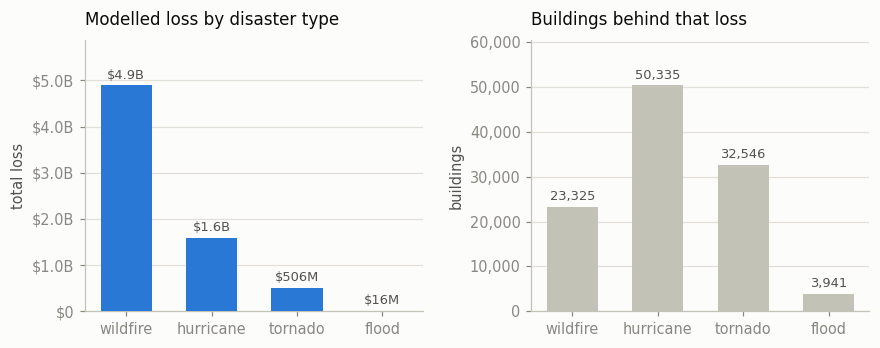

In [ ]:
order = by_type.sort_values('loss', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
fig.subplots_adjust(wspace=0.32)

#Left: the money. 
#Right: how many buildings produced it.
bars(axes[0], order['loss'], RAMP[2], money)
style(axes[0], title='Modelled loss by disaster type', ylabel='total loss')

bars(axes[1], order['buildings'], NEUTRAL, count)
style(axes[1], title='Buildings behind that loss', ylabel='buildings')

for ax in axes:
    ax.set_xticks(range(len(order)), order.index)

fig.savefig(OUTPUT_DIR / 'cost_by_disaster_type.png')
plt.show()

## 4. Price Check Against Flood Insurance Records

The National Flood Insurance Program provides records for settled claims, including a census block-group code. This allows us to compare the model’s estimated losses for the four water-related events with the actual damage amounts recorded by insurance adjusters on site.


In [ ]:
#Settlement is the building payout plus the contents payout
claims = claims[claims['censusGeoid'].isin(set(tracts['GEOID']))].copy()
claims['paid'] = (claims['amountPaidOnBuildingClaim'].fillna(0)
                  + claims['amountPaidOnContentsClaim'].fillna(0))

#A block group belongs to one event, so its most common event stands for it
event_of_block = buildings.groupby('GEOID')['event_name'].agg(lambda s: s.value_counts().idxmax())
claims['event_name'] = claims['censusGeoid'].map(event_of_block)

print(f'NFIP claims inside the analysis block groups: {len(claims):,}')

NFIP claims inside the analysis block groups: 6,525


In [ ]:
#What we say a damaged building lost, per water event.
modelled = (buildings[buildings['event_name'].isin(WATER_EVENTS) & buildings['damaged']]
            .groupby('event_name')['loss']
            .agg(damaged='size', modelled='mean'))

#What an adjuster measured on site and what the insurer actually paid.
insured = claims.groupby('event_name').agg(
    claims=('paid', 'size'),
    assessed=('buildingDamageAmount', 'mean'),
    paid=('amountPaidOnBuildingClaim', 'mean'))

price_check = modelled.join(insured)
price_check['modelled_over_assessed'] = price_check['modelled'] / price_check['assessed']
price_check.to_csv(OUTPUT_DIR / 'price_check_vs_nfip.csv')

display(price_check.round(2))

,damaged,modelled,claims,assessed,paid,modelled_over_assessed
event_name,,,,,,
hurricane-florence,1031,32558.71,277,102175.09,105290.35,0.32
hurricane-harvey,11325,112394.62,5121,154390.59,144871.77,0.73
hurricane-michael,10770,26466.09,1118,30978.77,32211.17,0.85
midwest-flooding,365,44838.11,9,78056.56,63385.88,0.57


The modelled losses are around 0.32 – 0.85 of the amounts assessed by insurers. In other words, they are in the right range but consistently on the lower side. We therefore treat all dollar estimates below as conservative.


## 5. Price Check for Fire and Other Disaster Types

Floods are not the only type of disaster we can validate. They are simply the only one with publicly available insurance settlement records. For the other disaster types, we use two additional sources.

**CAL FIRE DINS.** After a wildfire in California, CAL FIRE inspects structures within the affected area and records the share of the structure that was damaged using four categories: `Affected (>0-10%)`, `Minor (10-25%)`, `Major (25-50%)`, and `Destroyed (>50%)`. 

These categories give us an empirical way to check the loss ratios used in our model. We compare them against 9,395 structures across the three fires in our dataset.

**FEMA verified loss.** For each disaster type, FEMA records `rpfvl`, the verified real property loss in dollars, for households that apply for assistance. This measures something slightly different from replacement cost: it represents the amount of damage recognized by the aid programme. We therefore treat it as a lower bound rather than a direct like-for-like comparison. The analysis is limited to the counties covered by our imagery.


In [ ]:
#CAL FIRE records a damage band, which means that each band takes the midpoint of its range.
DINS_RATIO = {'No Damage': 0.0,
              'Affected (>0-10%)': 0.05,
              'Minor (10-25%)': 0.175,
              'Major (25-50%)': 0.375,
              'Destroyed (>50%)': 1.0}

dins['ratio'] = dins['DAMAGE'].map(DINS_RATIO)
dins['destroyed'] = dins['DAMAGE'] == 'Destroyed (>50%)'

display(dins['DAMAGE'].value_counts().rename('inspected structures'))

DAMAGE
Destroyed (>50%)     8390
Affected (>0-10%)     568
Minor (10-25%)        211
Major (25-50%)        133
No Damage              93
Name: inspected structures, dtype: int64

In [ ]:
#Damaged structures only (CAL FIRE inspects the burn scar, we cover the whole scene)
inspected = dins[dins['ratio'] > 0]
labelled = buildings[buildings['damaged'] & (buildings['disaster_type'] == 'wildfire')]

calfire = inspected.groupby('event_name').agg(
    inspected_structures=('ratio', 'size'),
    calfire_loss_ratio=('ratio', 'mean'),
    calfire_destroyed_share=('destroyed', 'mean'))

ours = labelled.groupby('event_name').agg(
    labelled_buildings=('ratio', 'size'),
    our_loss_ratio=('ratio', 'mean'),
    our_destroyed_share=('destroyed', 'mean'))

#The last column is the whole point: how far our assumption sits from their measurement
fire_check = calfire.join(ours)
fire_check['ours_over_calfire'] = fire_check['our_loss_ratio'] / fire_check['calfire_loss_ratio']
fire_check.to_csv(OUTPUT_DIR / 'price_check_vs_calfire.csv')

print(f'CAL FIRE measured a mean loss of {inspected["ratio"].mean():.1%} of a structure')
print(f'Our loss ratios assume {labelled["ratio"].mean():.1%}')

display(fire_check.round(3))

CAL FIRE measured a mean loss of 91.4% of a structure
Our loss ratios assume 93.2%


,inspected_structures,calfire_loss_ratio,calfire_destroyed_share,labelled_buildings,our_loss_ratio,our_destroyed_share,ours_over_calfire
event_name,,,,,,,
santa-rosa-wildfire,5949,0.957,0.951,2169,0.977,0.972,1.021
socal-fire,1346,0.836,0.811,1255,0.915,0.896,1.094
woolsey-fire,2007,0.842,0.819,1281,0.875,0.852,1.039


Averaged across damaged structures, CAL FIRE inspections estimate an average loss of 91.4%, while our mapping gives 93.2%. This means the wildfire loss ratios used in our model are within about two percentage points of the damage recorded by on-site inspectors.


In [ ]:
registrations['insured'] = registrations['homeOwnersInsurance'].astype(str).str.lower() == 'true'
registrations['disaster_type'] = registrations['event_name'].map(DISASTER_TYPE)

#Our own average loss per damaged building, event by event.
modelled_per_event = (buildings[buildings['damaged']]
                      .groupby('event_name')['loss']
                      .agg(damaged_buildings='size', modelled_loss='mean'))

#What a FEMA inspector verified for the households that applied for aid.
federal = registrations.groupby('event_name').agg(
    households=('rpfvl', 'size'),
    fema_verified_loss=('rpfvl', 'mean'),
    fema_grant=('ihpAmount', 'mean'),
    insured_share=('insured', 'mean'))

federal_check = modelled_per_event.join(federal)
federal_check['disaster_type'] = federal_check.index.map(DISASTER_TYPE)
federal_check['modelled_over_verified'] = (federal_check['modelled_loss']
                                           / federal_check['fema_verified_loss'])

federal_check = federal_check.sort_values(['disaster_type', 'event_name'])
federal_check.to_csv(OUTPUT_DIR / 'price_check_vs_fema.csv')

display(federal_check.round(2))

,damaged_buildings,modelled_loss,households,fema_verified_loss,fema_grant,insured_share,disaster_type,modelled_over_verified
event_name,,,,,,,,
midwest-flooding,365,44838.11,905,8311.53,5903.59,0.60,flood,5.39
hurricane-florence,1031,32558.71,5908,7651.00,4550.34,0.61,hurricane,4.26
hurricane-harvey,11325,112394.62,103045,9315.79,6404.32,0.71,hurricane,12.06
hurricane-michael,10770,26466.09,17518,6168.03,3347.11,0.58,hurricane,4.29
joplin-tornado,3942,59208.53,1287,33796.53,3679.19,0.73,tornado,1.75
moore-tornado,2356,82842.01,1508,17398.58,1907.48,0.73,tornado,4.76
tuscaloosa-tornado,1895,40703.71,2256,11751.39,2660.68,0.72,tornado,3.46
santa-rosa-wildfire,2169,487860.05,333,120751.10,8298.96,0.75,wildfire,4.04
socal-fire,1255,1517161.30,146,71407.38,8265.71,0.66,wildfire,21.25


We now have a dollar estimate for each disaster type. FEMA’s verified losses are much lower than our modelled costs, which is expected: FEMA records the damage it considers eligible for assistance, rather than the full cost of rebuilding.

The last column should therefore be read as a rough ceiling on how much federal aid can cover, not as evidence that our modelled costs are too high.



## 6. Damage and Cost Across Income

In [ ]:
#Roll the buildings up to block groups, the unit everything below works in.
blocks = buildings.groupby('GEOID').agg(
    buildings=('loss', 'size'),
    damaged=('damaged', 'sum'),
    loss=('loss', 'sum'),
    damage_ratio=('ratio', 'mean'))

blocks['loss_per_building'] = blocks['loss'] / blocks['buildings']
blocks = blocks.join(tracts.set_index('GEOID')[['income_2017', 'renter_pct_2017']])
blocks['event_name'] = event_of_block

print(f'Block groups in the analysis: {len(blocks):,}')

Block groups in the analysis: 295


In [ ]:
def income_tercile(income):
    #A few events are too small to cut into three, so everything there counts as mid
    if income.nunique() < 3:
        return pd.Series('mid', index=income.index)

    ranked = income.rank(method='first')
    return pd.qcut(ranked, 3, labels=['low', 'mid', 'high']).astype(str)


#Quintiles pool every event; terciles rank income inside one event, disaster held constant
blocks['quintile'] = pd.qcut(blocks['income_2017'], 5, labels=[f'Q{i}' for i in range(1, 6)])
blocks['tercile'] = blocks.groupby('event_name')['income_2017'].transform(income_tercile)


quintiles = blocks.groupby('quintile', observed=True).agg(
    block_groups=('buildings', 'size'),
    buildings=('buildings', 'sum'),
    median_income=('income_2017', 'median'),
    damage_ratio=('damage_ratio', 'mean'),
    loss_per_building=('loss_per_building', 'mean'))



terciles = blocks.groupby('tercile').agg(
    block_groups=('buildings', 'size'),
    damage_ratio=('damage_ratio', 'mean'),
    loss_per_building=('loss_per_building', 'mean')).reindex(['low', 'mid', 'high'])

quintiles.to_csv(OUTPUT_DIR / 'income_quintiles.csv')
terciles.to_csv(OUTPUT_DIR / 'within_event_terciles.csv')

display(quintiles.round(3))
display(terciles.round(3))

,block_groups,buildings,median_income,damage_ratio,loss_per_building
quintile,,,,,
Q1,59,26694,31850.0,0.106,12534.356
Q2,59,20925,47386.0,0.061,10553.701
Q3,59,16664,62019.0,0.065,12204.345
Q4,59,21503,82222.0,0.089,28424.435
Q5,59,24361,135688.0,0.121,88888.119


,block_groups,damage_ratio,loss_per_building
tercile,,,
low,98,0.091,19052.333
mid,97,0.072,20053.499
high,100,0.101,51913.743


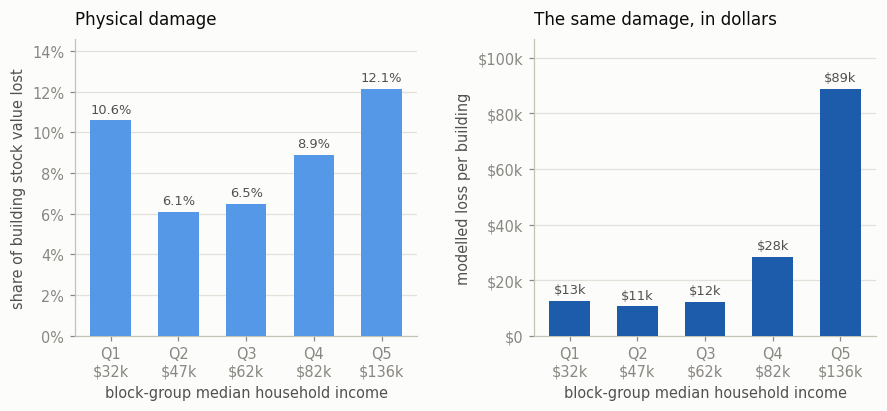

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
fig.subplots_adjust(wspace=0.34)

#Left: the share of building value destroyed. 
#Right: the same map priced in dollars.
bars(axes[0], quintiles['damage_ratio'], RAMP[1], lambda v: f'{v:.1%}', pct)
style(axes[0], title='Physical damage', ylabel='share of building stock value lost')

bars(axes[1], quintiles['loss_per_building'], RAMP[3], money)
style(axes[1], title='The same damage, in dollars', ylabel='modelled loss per building')

#Each tick names the quintile and the income that defines it
ticks = [f'{q}\n{money(i)}' for q, i in zip(quintiles.index, quintiles['median_income'])]

for ax in axes:
    ax.set_xticks(range(len(quintiles)), ticks)
    ax.set_xlabel('block-group median household income')

fig.savefig(OUTPUT_DIR / 'damage_vs_dollars.png')
plt.show()

The share of building value destroyed changes very little across income groups and shows no clear upward or downward trend, which is consistent with the null result from Notebook 1.

However, once we put the same damage into dollar terms, the losses increase sharply with income. This pattern remains even within a single event, where the disaster itself is held constant. A relief system based on dollar damage would therefore favour wealthier neighbourhoods by design.


## 7. Who Can Pay for the Rebuild

Households can get recovery money through two main channels: an insurance settlement or a FEMA grant through the Individuals and Households Program. Since public settlement records are only available for floods, this section focuses on the four water events. Section 8 extends the insurance analysis to all disaster types.

A filed insurance claim for each damaged building gives us a lower bound on coverage. The FEMA estimate provides an upper bound: for every damaged building without a claim, we assign the average approved award for that event. This is deliberately generous, since not every applicant is approved for assistance.


In [ ]:
DISASTER_NUMBER = {'hurricane-harvey': 4332,
                   'hurricane-florence': 4393,
                   'hurricane-michael': 4399,
                   'midwest-flooding': 4438,
                   'santa-rosa-wildfire': 4344,
                   'socal-fire': 4353,
                   'woolsey-fire': 4407,
                   'joplin-tornado': 1980,
                   'tuscaloosa-tornado': 1971,
                   'moore-tornado': 4117}



#Average approved FEMA grant per household, looked up by declaration number
fema['ihp_per_household'] = fema['totalAmountIhpApproved'] / fema['totalNumberIaApproved']
grant = fema.set_index('disasterNumber')['ihp_per_household']

ihp = {event: grant[number] for event, number in DISASTER_NUMBER.items()}



#The water events, with their flood claims joined on
paid_by_block = claims.groupby('censusGeoid').agg(
    claims=('paid', 'size'),
    nfip_paid=('paid', 'sum'))

flood = blocks[blocks['event_name'].isin(WATER_EVENTS)].join(paid_by_block)
flood = flood.fillna({'claims': 0, 'nfip_paid': 0})
flood = flood[flood['damaged'] >= 10].copy()

print(f'Flood-event block groups with 10 or more damaged buildings: {len(flood):,}')

Flood-event block groups with 10 or more damaged buildings: 115


In [ ]:
#Credit every damaged building without a claim with the event's average approved grant
flood['claims_per_damaged'] = flood['claims'] / flood['damaged']
flood['fema'] = np.maximum(flood['damaged'] - flood['claims'], 0) * flood['event_name'].map(ihp)
flood['quartile'] = pd.qcut(flood['income_2017'], 4, labels=['Q1 poorest', 'Q2', 'Q3', 'Q4 richest'])

who_pays = flood.groupby('quartile', observed=True).agg(
    block_groups=('buildings', 'size'),
    median_income=('income_2017', 'median'),
    damaged=('damaged', 'sum'),
    claims=('claims', 'sum'),
    loss=('loss', 'sum'),
    nfip_paid=('nfip_paid', 'sum'),
    fema=('fema', 'sum'),
    renter=('renter_pct_2017', 'median'))

#Split the repair bill three ways: insurance, federal grants, and nobody
who_pays['insured_share'] = who_pays['claims'] / who_pays['damaged']
who_pays['insurance_pct'] = 100 * who_pays['nfip_paid'] / who_pays['loss']
who_pays['federal_aid_pct'] = 100 * who_pays['fema'] / who_pays['loss']
who_pays['uncovered_pct'] = 100 - who_pays['insurance_pct'] - who_pays['federal_aid_pct']
who_pays['loss_per_damaged'] = who_pays['loss'] / who_pays['damaged']

who_pays.to_csv(OUTPUT_DIR / 'who_pays.csv')

rho, pvalue = stats.spearmanr(flood['income_2017'], flood['claims_per_damaged'])

print(f'Claims per damaged building vs income: Spearman rho = {rho:.2f} (p = {pvalue:.1e})')
print(f'Mean NFIP payout per claim: {money(claims["paid"].mean())}')
print(f'Mean FEMA grant per approved household: {money(fema["ihp_per_household"].mean())}')

summary = ['block_groups',
           'median_income',
           'damaged',
           'insured_share',
           'loss_per_damaged',
           'insurance_pct',
           'federal_aid_pct',
           'uncovered_pct',
           'renter']

display(who_pays[summary].round(2))

Claims per damaged building vs income: Spearman rho = 0.62 (p = 2.1e-13)
Mean NFIP payout per claim: $146k
Mean FEMA grant per approved household: $5,708


,block_groups,median_income,damaged,insured_share,loss_per_damaged,insurance_pct,federal_aid_pct,uncovered_pct,renter
quartile,,,,,,,,,
Q1 poorest,29,34677.0,6461,0.08,26609.19,22.84,16.17,60.99,0.52
Q2,29,46339.0,3366,0.17,28961.52,46.62,15.09,38.30,0.37
Q3,28,77799.0,6776,0.26,55859.26,55.16,6.24,38.60,0.17
Q4 richest,29,136034.0,6847,0.47,139921.09,64.38,1.75,33.88,0.08


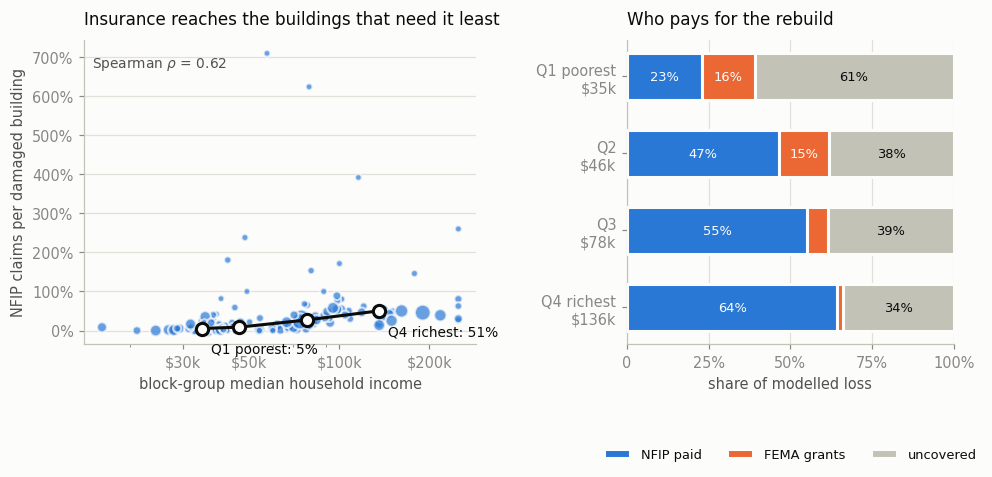

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6), gridspec_kw={'width_ratios': [1.2, 1]})
fig.subplots_adjust(wspace=0.42)

#Right panel: the repair bill as three stacked shares of the loss.
ax = axes[1]
left = np.zeros(len(who_pays))

channels = [('insurance_pct', BLUE, 'NFIP paid'),
            ('federal_aid_pct', ORANGE, 'FEMA grants'),
            ('uncovered_pct', NEUTRAL, 'uncovered')]

for column, color, label in channels:
    ax.barh(range(len(who_pays)), who_pays[column], 0.6, left=left, color=color, label=label,
            zorder=3, edgecolor=SURFACE, linewidth=2)

    #Label a segment only when it is wide enough to hold the text.
    for i, (share, offset) in enumerate(zip(who_pays[column], left)):
        if share > 8:
            ax.text(offset + share / 2, i, f'{share:.0f}%', ha='center', va='center', fontsize=8.5,
                    color=INK if color == NEUTRAL else SURFACE)

    left += who_pays[column].to_numpy()

quartile_labels = [f'{q}\n{money(i)}' for q, i in zip(who_pays.index, who_pays['median_income'])]

ax.set_yticks(range(len(who_pays)), quartile_labels)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100], ['0', '25%', '50%', '75%', '100%'])
ax.invert_yaxis()
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.42), ncols=3, fontsize=8.5)

style(ax, axis='x', title='Who pays for the rebuild', xlabel='share of modelled loss')

fig.savefig(OUTPUT_DIR / 'who_pays.png')
plt.show()
#The quartile medians, joined up so the trend reads through the scatter.
medians = flood.groupby('quartile', observed=True).agg(
    x=('income_2017', 'median'),
    y=('claims_per_damaged', 'median'))

ax.plot(medians['x'], medians['y'], color=INK, lw=2, marker='o', ms=8, zorder=4,
        markerfacecolor=SURFACE, markeredgewidth=2)

for label in [medians.index[0], medians.index[-1]]:
    row = medians.loc[label]
    ax.annotate(f'{label}: {row["y"]:.0%}', (row['x'], row['y']), textcoords='offset points',
                xytext=(6, -16), fontsize=9, color=INK, zorder=5)

income_ticks = [30000, 50000, 100000, 200000]
income_labels = ['$30k', '$50k', '$100k', '$200k']

ax.set_xscale('log')
ax.set_xticks(income_ticks, income_labels)
ax.yaxis.set_major_formatter(lambda v, _: pct(v))
ax.text(0.02, 0.95, f'Spearman $\\rho$ = {rho:.2f}', transform=ax.transAxes, fontsize=9,
        color=LABEL, va='top')

style(ax, title='Insurance reaches the buildings that need it least',
      xlabel='block-group median household income', ylabel='NFIP claims per damaged building')

#Right panel: the repair bill as three stacked shares of the loss
ax = axes[1]
left = np.zeros(len(who_pays))

channels = [('insurance_pct', BLUE, 'NFIP paid'),
            ('federal_aid_pct', ORANGE, 'FEMA grants'),
            ('uncovered_pct', NEUTRAL, 'uncovered')]

for column, color, label in channels:
    ax.barh(range(len(who_pays)), who_pays[column], 0.6, left=left, color=color, label=label,
            zorder=3, edgecolor=SURFACE, linewidth=2)

    #Label a segment only when it is wide enough to hold the text
    for i, (share, offset) in enumerate(zip(who_pays[column], left)):
        if share > 8:
            ax.text(offset + share / 2, i, f'{share:.0f}%', ha='center', va='center', fontsize=8.5,
                    color=INK if color == NEUTRAL else SURFACE)

    left += who_pays[column].to_numpy()

quartile_labels = [f'{q}\n{money(i)}' for q, i in zip(who_pays.index, who_pays['median_income'])]

ax.set_yticks(range(len(who_pays)), quartile_labels)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100], ['0', '25%', '50%', '75%', '100%'])
ax.invert_yaxis()
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.42), ncols=3, fontsize=8.5)

style(ax, axis='x', title='Who pays for the rebuild', xlabel='share of modelled loss')

fig.savefig(OUTPUT_DIR / 'who_pays.png')
plt.show()

Insurance covers about 23% of the modelled loss in the poorest income quartile, compared with 64% in the richest. For the poorest households, FEMA grants are the main source of recovery support, but they typically amount to only a few thousand dollars against repair costs in the five-figure range.

As a result, around 61% of their estimated loss remains uncovered. This is the part of the inequality that the damage map alone cannot capture, and it comes from actual payout records rather than modelled estimates.


## 8. Insurance Across Every Disaster Type

FEMA asks every applicant whether their home was insured, which lets us look at insurance coverage for fire and tornado households as well. There are two important caveats to keep in mind.

First, these are households that applied for federal assistance, not the general population. People with full insurance coverage may never apply for FEMA aid, so the overall insurance rates are likely biased downward.

Second, verified *real property* loss is only recorded for owner-occupants. This means we are measuring homeowners’ insurance coverage among homeowners, rather than insurance coverage across all households.

The comparisons across income groups within this population are still useful, and this is the only evidence we have that allows us to compare insurance coverage across different disaster types.


In [ ]:
#A verified property loss only exists for owners, so track how many of these applicants own.
registrations['owner'] = registrations['ownRent'].astype(str).str.upper().str.startswith('O')

insurance_by_type = registrations.groupby('disaster_type').agg(
    households=('insured', 'size'),
    insured_share=('insured', 'mean'),
    verified_loss=('rpfvl', 'mean'),
    fema_grant=('ihpAmount', 'mean'),
    owner_share=('owner', 'mean'))

insurance_by_type.to_csv(OUTPUT_DIR / 'insurance_by_disaster_type.csv')

display(insurance_by_type.round(3))

,households,insured_share,verified_loss,fema_grant,owner_share
disaster_type,,,,,
flood,905,0.598,8311.527,5903.589,0.998
hurricane,126471,0.685,8802.011,5894.246,0.999
tornado,5051,0.725,19054.507,2695.326,0.993
wildfire,813,0.753,99122.627,8455.495,0.994


In [ ]:
def income_floor(band):
    #Sorts the bands, keeping '<$15,000' below the band that starts at $15,000.
    text = str(band)
    digits = ''.join(character for character in text.split('-')[0] if character.isdigit())
    value = int(digits) if digits else 0

    return value - 1 if text.startswith('<') else value


#A gross income of 0 means the applicant did not report one, so drop those rows.
reported = registrations[registrations['grossIncome'].astype(str) != '0']
bands = sorted(reported['grossIncome'].dropna().unique(), key=income_floor)

by_income = reported.groupby('grossIncome').agg(
    households=('insured', 'size'),
    insured_share=('insured', 'mean'),
    verified_loss=('rpfvl', 'mean'),
    fema_grant=('ihpAmount', 'mean')).reindex(bands)

by_income.to_csv(OUTPUT_DIR / 'insurance_by_income_band.csv')

display(by_income.round(3))

,households,insured_share,verified_loss,fema_grant
grossIncome,,,,
"<$15,000",16494,0.382,6722.050,5616.931
"$15,000-$30,000",25265,0.514,7573.164,5587.732
"$30,001-$60,000",33030,0.718,8718.344,5309.065
"$60,001-$120,000",25244,0.878,10854.204,5764.437
"$120,001-$175,000",7334,0.955,14442.202,7104.605
">$175,000",7825,0.948,18692.136,7534.633


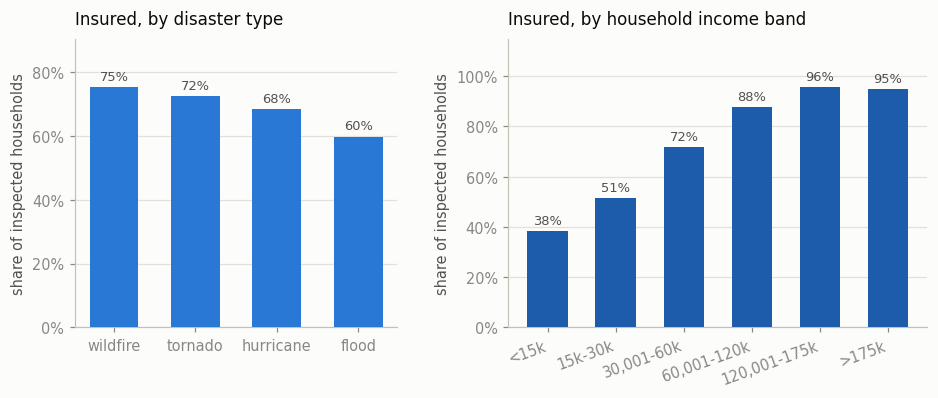

In [ ]:
order = insurance_by_type.sort_values('insured_share', ascending=False)

#Thin income bands would be noise, so the right panel keeps the well-populated ones
shown = by_income[by_income['households'] >= 200]
band_labels = [band.replace('$', '').replace(',000', 'k') for band in shown.index]

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.4), gridspec_kw={'width_ratios': [1, 1.3]})
fig.subplots_adjust(wspace=0.3)


bars(axes[0], order['insured_share'], RAMP[2], pct)
axes[0].set_xticks(range(len(order)), order.index)
style(axes[0], title='Insured, by disaster type', ylabel='share of inspected households')


bars(axes[1], shown['insured_share'], RAMP[3], pct)
axes[1].set_xticks(range(len(shown)), band_labels, rotation=20, ha='right')
style(axes[1], title='Insured, by household income band', ylabel='share of inspected households')

fig.savefig(OUTPUT_DIR / 'insurance_across_types.png')
plt.show()

Coverage runs from 38% in the poorest band to 95% in the richest, and the gradient holds for every
disaster type. It also corrects the flood-only picture: wildfire households are the best insured and
flood households the worst, because a standard homeowners policy covers fire and wind while flood
needs a separate NFIP policy.

## 9. The Same Rules on the Predicted Damage Map

`predictions.csv` contains the building-level outputs from the two Part 2 change-detection CNNs on the held-out splits, limited to buildings with available census geography.

We take a fixed relief budget and distribute it in two different ways, first using the actual damage labels and then using the predicted damage map. For each, we apply two rules: an equal payment per damaged building and a payment proportional to the estimated dollar loss.

The difference between the two results shows how much the automated predictions can change the distribution of relief.


In [ ]:
BUDGET = 1e9
TERCILES = ['low', 'mid', 'high']

#Two ways to spend a fixed relief budget.
#The rule is the policy, before any model error.
RULES = {'per damaged building': lambda frame, column: (frame[column] > 0).astype(float),
         'proportional to loss': lambda frame, column: frame[column]}

#Price the held-out buildings twice: once from the labels, once from the model.
home_value = predictions['median_home_value_2017']
predictions['true_loss'] = home_value * predictions['damage_class'].map(LOSS_RATIO)
predictions['pred_loss'] = home_value * predictions['pred_class'].map(LOSS_RATIO)

predictions['tercile'] = predictions['GEOID'].map(blocks['tercile'])
predictions['domain'] = np.where(predictions['split'] == 'test_ood',
                                 'unseen type (wildfire)', 'seen types')

predictions = predictions[predictions['tercile'].notna()]

print(f'Held-out rows with census geography: {len(predictions):,}')

Held-out rows with census geography: 24,876


In [ ]:
def shares(frame, weight):
    #How a budget splits across the three income terciles under one weighting
    weight = pd.Series(np.asarray(weight, float), index=pd.Index(frame['tercile'], name='tercile'))
    return (weight.groupby(level=0).sum() / weight.sum()).reindex(TERCILES).fillna(0)


AUDIT_COLUMNS = ['model',
                 'rule',
                 'domain',
                 'tercile',
                 'truth',
                 'predicted',
                 'shift_per_1B']

audit = []

#One table per model, domain and rule: where the money lands, truth against prediction
for (model, domain), frame in predictions.groupby(['model', 'domain']):
    for rule, weigh in RULES.items():

        table = pd.DataFrame({'truth': shares(frame, weigh(frame, 'true_loss')),
                              'predicted': shares(frame, weigh(frame, 'pred_loss'))})

        table['shift_per_1B'] = (table['predicted'] - table['truth']) * BUDGET
        audit.append(table.assign(model=model, rule=rule, domain=domain))

audit = pd.concat(audit).reset_index()[AUDIT_COLUMNS]
audit.to_csv(OUTPUT_DIR / 'allocation_audit.csv', index=False)

print(f'Audit rows: {len(audit)}')

Audit rows: 24


In [ ]:
#Halved because every dollar that leaves one tercile arrives in another
misdirected = (audit.assign(absolute=audit['shift_per_1B'].abs())
               .groupby(['model', 'domain', 'rule'])['absolute'].sum() / 2)

best = predictions[predictions['model'] == 'pretrained']

print(f'Buildings audited: {best["uid"].nunique():,} '
      f'in {best["event"].nunique()} events, {best["GEOID"].nunique()} block groups')
print(f'Events covered: {sorted(best["event"].unique())}')
print(f'The predicted map reports '
      f'{best["pred_loss"].sum() / best["true_loss"].sum():.0%} of the true dollar loss')

print('\nDollars per $1B landing in a different income tercile than the labels would send them:')
print(misdirected.apply(money).to_string())

Buildings audited: 12,438 in 7 events, 122 block groups
Events covered: ['hurricane-florence', 'hurricane-harvey', 'hurricane-michael', 'midwest-flooding', 'santa-rosa-wildfire', 'socal-fire', 'woolsey-fire']
The predicted map reports 119% of the true dollar loss

Dollars per $1B landing in a different income tercile than the labels would send them:
model       domain                  rule                
pretrained  seen types              per damaged building     $30M
                                    proportional to loss     $66M
            unseen type (wildfire)  per damaged building    $188M
                                    proportional to loss    $107M
scratch     seen types              per damaged building     $36M
                                    proportional to loss     $66M
            unseen type (wildfire)  per damaged building    $171M
                                    proportional to loss    $127M


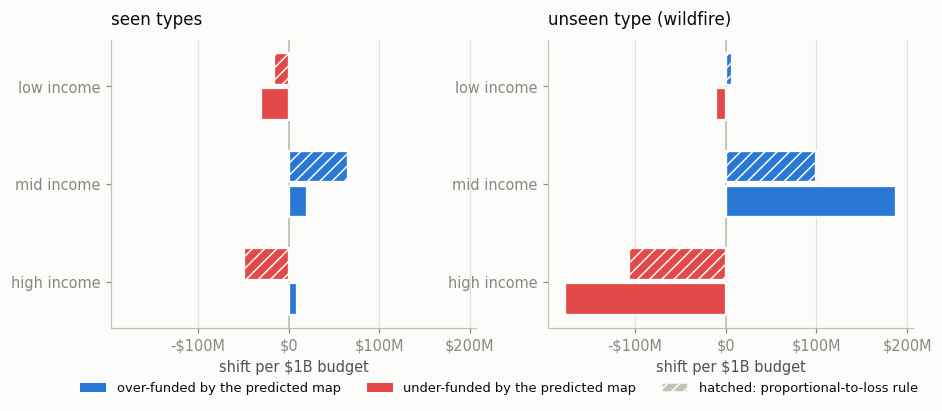

In [ ]:
shown = audit[audit['model'] == 'pretrained']

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4), sharex=True)

#Blue means the predicted map over-funds that tercile 
#Red means it under-funds it
for ax, (domain, frame) in zip(axes, shown.groupby('domain')):
    table = frame.pivot(index='tercile', columns='rule', values='shift_per_1B').reindex(TERCILES)
    y, height = np.arange(len(table)), 0.36

    for i, (rule, values) in enumerate(table.items()):
        colors = [BLUE if v >= 0 else RED for v in values]
        hatch = '///' if rule == 'proportional to loss' else None

        ax.barh(y + (0.5 - i) * height, values, height * 0.9, color=colors, hatch=hatch,
                zorder=3, edgecolor=SURFACE, linewidth=1.5)

    ax.axvline(0, color=NEUTRAL, lw=1.2)
    ax.set_yticks(y, [f'{t} income' for t in table.index])
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.xaxis.set_major_formatter(lambda v, _: money(v))
    ax.invert_yaxis()

    style(ax, axis='x', title=domain, xlabel='shift per $1B budget')

handles = [mpl.patches.Patch(facecolor=BLUE,
                             label='over-funded by the predicted map'),
           mpl.patches.Patch(facecolor=RED,
                             label='under-funded by the predicted map'),
           mpl.patches.Patch(facecolor=NEUTRAL, hatch='///', edgecolor=SURFACE,
                             label='hatched: proportional-to-loss rule')]

fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncols=3, fontsize=8.5)

fig.savefig(OUTPUT_DIR / 'model_misallocation.png')
plt.show()

The audit covers the three wildfire events and four water events. The three tornado events are entirely part of the training split, so they do not have a held-out test set or an automated damage map.

For disaster types the model has seen before, the predicted map shifts around $30–66M out of every $1B into a different income tercile. For wildfire, which the model was never trained on, the shift is much larger at $107 – 188M.

The direction is also consistent: the predicted map tends to add damage to middle-income block groups while taking funding away from higher-income areas, where the fires actually caused the most housing destruction.


## 10. Interpretation and Limitations

The cost layer covers all four disaster types, and each one now has an independent price check: flood settlements for the water events, CAL FIRE inspections for wildfires, and FEMA verified losses across all disaster types. What remains flood-specific is the recovery analysis in Section 7, since NFIP is the only programme that publishes settlement data at the property level.

Tornado loss ratios are still the weakest part of the analysis. There is no inspection dataset comparable to DINS for tornadoes, so their contribution to total losses depends entirely on the assumed ratios.

The socioeconomic analysis is based on block-group averages and should not be interpreted at the individual household level. We use one median home value for every building within a block group, while four loss ratios are used to represent what is actually a continuous range of damage. The low/high sensitivity band shows how much this assumption affects the overall estimates.

Insurance coverage from NFIP is inferred from filed claims, so it should be treated as a lower bound rather than the true coverage rate. Similarly, the FEMA coverage estimate describes households that applied for assistance, not the general population. Federal aid is also estimated generously.

Finally, the predicted-map audit uses models retrained locally on half of the available patches. Their performance metrics are reported in the folder README rather than being carried over from Part 2.
